# Human-likeness: how people move, against the models (11/22/26)

Fitting the student to people has used three numbers: solve rate, moves / optimal, and how they change over trials.
Many very different solvers can match those. This notebook compares people with candidate models **move by move**,
on the 70 layouts people played (Olieslagers et al. 2023; 42 participants, every attempt, solved or not), to find
which measures tell the models apart - and so which to fit on.

`experiments/human_profile.py` writes one table, a row per move, for people and for each model (10 runs per layout,
capped at max(50, 10 × optimal), no giving up):

| source | what it is |
|---|---|
| people | every attempt, replayed into boards |
| AND-OR (paper) | Olieslagers et al.'s per-board AND-OR distribution, γ 0.07 (its best fit to people's moves) |
| AND-OR (network) | AND-OR ordered by the start network's dest head, γ 0.07 (the apprentice's teacher) |
| intuition | the start network's policy, temperature 1, 10-board memory (the session student) |
| forward | the forward planner on the start network: K8 D4, λ 16, novelty half-life 80 |
| random | uniform legal moves, 10-board memory |
| intuition, soft memory | the intuition student with the fitted soft memory in place of the 10-board rule (section 8) |
| forward, soft memory | the forward planner with the same soft memory |
| forward, fitted | the planner with its novelty fitted to people's revisits (section 9): λ 2, novelty half-life 2 |
| value planner, soft memory | the planner with no novelty at all (rollouts ranked by the value head), soft memory |

Per-move measures are pooled over moves, so long attempts weigh more; models never give up, so their long, stuck
attempts weigh more than people's.

In [1]:
import sys
sys.path.insert(0, "..")
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from rushhour import paths

INK, MUTED, RULE, GRID = "#1f1f1d", "#5f5e5a", "#b5b4ad", "#e6e5e0"
SOURCES = {"people": "#1f1f1d", "AND-OR (paper)": "#2a78d6", "AND-OR (network)": "#08306b", "intuition": "#e6a00d",
           "forward": "#e6550d", "random": "#b5b4ad", "intuition, soft memory": "#c9a227",
           "forward, soft memory": "#a63603", "forward, fitted": "#7a0177", "value planner, soft memory": "#41ab5d"}
ROLES = ["red", "depth 1", "depth 2", "depth 3+", "not in tree", "tree too large"]
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 110,
                     "legend.frameon": False, "legend.fontsize": 8.5})


def tidy(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


mv = pd.read_csv(os.path.join(paths.MODELS, "summary", "human_profile", "moves.csv.gz"), dtype={"who": str})
mv["source"] = pd.Categorical(mv.source, list(SOURCES))
att = (mv.groupby(["source", "who", "instance", "attempt"], observed=True)
       .agg(moves=("move", "size"), solved=("solved", "first"), optimal=("optimal length", "first"),
            trial=("trial", "first")).reset_index())
att["ratio"] = att.moves / att.optimal
overview = att.groupby("source", observed=True).agg(attempts=("moves", "size"), moves=("moves", "sum"),
                                                     solved=("solved", "mean"))
overview["moves / optimal (solved)"] = att[att.solved].groupby("source", observed=True).ratio.mean()
overview.round(3)

,attempts,moves,solved,moves / optimal (solved)
source,,,,
people,2804,62313,0.703,2.087
AND-OR (paper),700,62957,0.470,5.248
AND-OR (network),700,38853,0.754,2.629
intuition,700,50486,0.636,3.679
forward,700,24789,0.924,2.294
random,700,75700,0.044,7.128
"intuition, soft memory",700,53898,0.583,3.815
"forward, soft memory",700,27934,0.900,2.456
"forward, fitted",700,32477,0.816,2.283


People's solve rate is with giving up and restarts (each restart is a new attempt); the models' is within the cap.

## 1. Which moves: chance of an optimal move by distance to the goal

A move is optimal if it brings the board one move closer to the goal, worse if it moves it further away. Distance 1
(red's path clear) is left out: people finish by dragging red off the board, which isn't recorded as a slide, so
their moves at distance 1 are only the rare ones made instead of finishing.

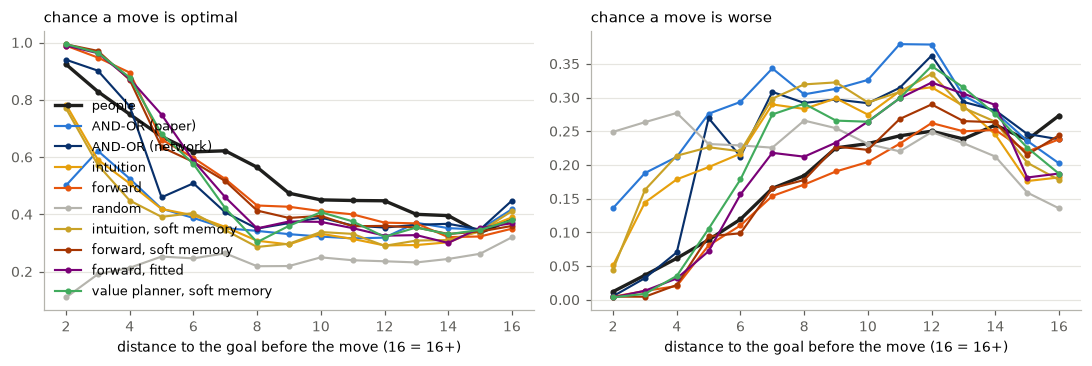

In [2]:
mv["dbin"] = mv.distance.clip(upper=16).where(mv.distance > 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
for ax, (name, col) in zip(axes, [("optimal", "optimal"), ("worse", "worse")]):
    for src, color in SOURCES.items():
        d = mv[mv.source == src]
        y = (d.after < d.distance) if col == "optimal" else (d.after > d.distance)
        m = y.groupby(d.dbin).mean()
        ax.plot(m.index, m.values, color=color, lw=2.2 if src == "people" else 1.4, marker="o", ms=3, label=src)
    ax.set_xlabel("distance to the goal before the move (16 = 16+)")
    ax.set_title(f"chance a move is {name}")
    tidy(ax)
axes[0].legend()
plt.tight_layout()
plt.show()

## 2. Where they go: revisits and how long ago

- **board seen**: the move leads to a board already visited in this attempt; **undo**: straight back to the board
  before;
- **placement seen**: the moved car lands where it has already stood in this attempt. Its age - how many moves ago
  that car was last there - is the empirical forgetting curve that a fading novelty memory would have to match.

In [3]:
rev = mv.groupby("source", observed=True)[["board seen", "undo", "placement seen", "new best"]].mean()
rev.round(3)

,board seen,undo,placement seen,new best
source,,,,
people,0.145,0.061,0.489,0.338
AND-OR (paper),0.245,0.052,0.785,0.079
AND-OR (network),0.360,0.159,0.727,0.161
intuition,0.117,0.000,0.751,0.109
forward,0.057,0.000,0.530,0.287
random,0.091,0.000,0.819,0.044
"intuition, soft memory",0.283,0.101,0.772,0.095
"forward, soft memory",0.131,0.042,0.576,0.249
"forward, fitted",0.297,0.068,0.694,0.195


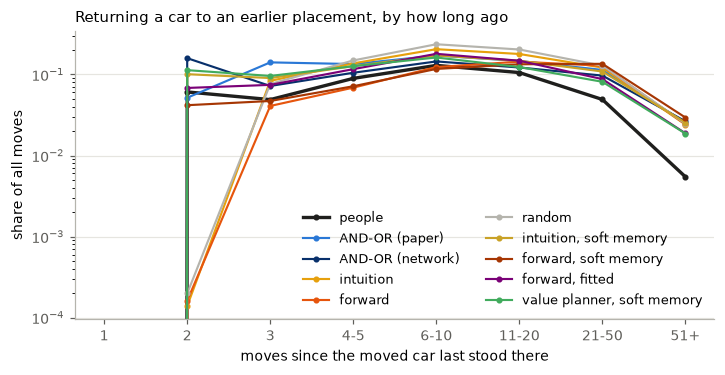

In [4]:
edges = [0, 1, 2, 3, 5, 10, 20, 50, 1000]
labels = ["1", "2", "3", "4-5", "6-10", "11-20", "21-50", "51+"]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for src, color in SOURCES.items():
    d = mv[mv.source == src]
    share = pd.cut(d["placement age"], edges, labels=labels).value_counts(sort=False) / len(d)
    ax.plot(labels, share.values, color=color, lw=2.2 if src == "people" else 1.4, marker="o", ms=3, label=src)
ax.set_yscale("log")
ax.set_xlabel("moves since the moved car last stood there")
ax.set_ylabel("share of all moves")
ax.set_title("Returning a car to an earlier placement, by how long ago")
ax.legend(ncol=2)
tidy(ax)
plt.show()

## 3. Which cars: the moved car's role in the AND-OR tree

On each board, Olieslagers et al.'s AND-OR tree gives every car a depth: red, its blockers (depth 1), their blockers
(depth 2), and so on; cars in no subgoal are "not in tree". Also: moving the same car twice in a row, and slides
that go as far as they can.

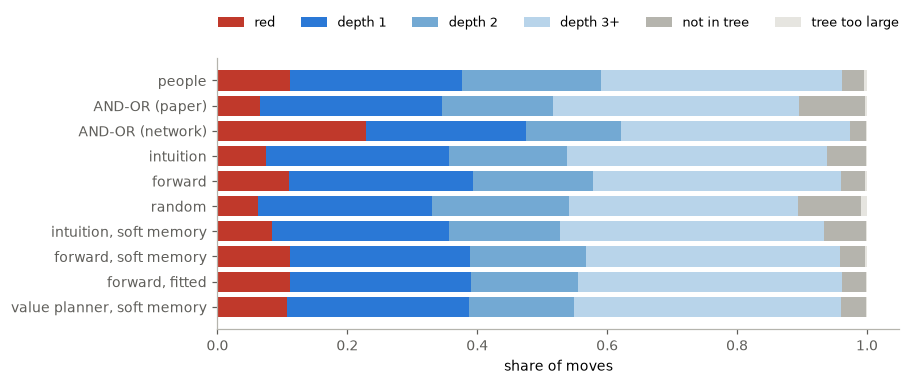

,red,depth 1,depth 2,depth 3+,not in tree,tree too large,same car,full slide,cells per move
source,,,,,,,,,
people,0.112,0.264,0.215,0.371,0.034,0.005,0.079,0.968,1.905
AND-OR (paper),0.066,0.279,0.171,0.380,0.101,0.003,0.118,0.724,1.665
AND-OR (network),0.229,0.245,0.147,0.353,0.024,0.002,0.262,0.747,1.610
intuition,0.074,0.282,0.183,0.399,0.060,0.002,0.124,0.737,1.638
forward,0.110,0.284,0.185,0.381,0.038,0.003,0.123,0.755,1.698
random,0.063,0.268,0.210,0.352,0.097,0.010,0.121,0.681,1.422
"intuition, soft memory",0.085,0.272,0.171,0.407,0.064,0.002,0.229,0.745,1.660
"forward, soft memory",0.112,0.277,0.179,0.391,0.038,0.003,0.164,0.754,1.686
"forward, fitted",0.112,0.279,0.164,0.407,0.038,0.001,0.199,0.762,1.695


In [5]:
roles = pd.crosstab(mv.source, mv.role, normalize="index").reindex(columns=[r for r in ROLES if r in set(mv.role)])
fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(len(roles))
palette = ["#c0392b", "#2a78d6", "#73a9d3", "#b8d4ea", "#b5b4ad", "#e6e5e0"]
for role, color in zip(roles.columns, palette):
    ax.barh(roles.index.astype(str), roles[role], left=left, color=color, label=role)
    left += roles[role].values
ax.invert_yaxis()
ax.set_xlabel("share of moves")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.2))
tidy(ax, grid=None)
plt.show()
slides = mv.groupby("source", observed=True).agg(**{"same car": ("same car", "mean"),
                                                    "full slide": ("full slide", "mean"),
                                                    "cells per move": ("steps", "mean")})
pd.concat([roles, slides], axis=1).round(3)

## 4. Puzzles: do the models find the same layouts hard?

Per layout: the solve rate, and the median moves / optimal - people's over all their attempts at the puzzle
(`human_data.trials`, unsolved included), the models' with an unsolved run counted at its cap. Spearman correlation
with people across the 70 layouts (people solve between 45% and 100% of each layout).

In [6]:
from rushhour import human_data as hd

tr = hd.trials()
ppl = tr.assign(ratio=tr.moves / tr.distance).groupby("instance").agg(ratio=("ratio", "median"),
                                                                      solved=("solved", "mean"))
rows = {}
for src in list(SOURCES)[1:]:
    m = att[att.source == src].groupby("instance").agg(ratio=("ratio", "median"), solved=("solved", "mean"))
    m = m.reindex(ppl.index)
    rows[src] = {"solve rate (r)": spearmanr(m.solved, ppl.solved).statistic,
                 "median moves / optimal (r)": spearmanr(m.ratio, ppl.ratio).statistic}
pd.DataFrame(rows).T.round(2)

C:\Users\yijos\AppData\Local\Temp\ipykernel_3584\2431353177.py:11: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "median moves / optimal (r)": spearmanr(m.ratio, ppl.ratio).statistic}


,solve rate (r),median moves / optimal (r)
AND-OR (paper),0.64,0.47
AND-OR (network),0.59,0.53
intuition,0.53,0.45
forward,0.48,0.49
random,0.26,NaN
"intuition, soft memory",0.63,0.44
"forward, soft memory",0.50,0.45
"forward, fitted",0.55,0.48
"value planner, soft memory",0.57,0.47


## 5. People over practice

Every measure by trial (the puzzle's place in the person's order), to see what changes as people gain experience -
what a model of expertise would have to reproduce.

In [7]:
ppl_mv = mv[mv.source == "people"].copy()
ppl_mv["block"] = pd.cut(ppl_mv.trial, [0, 10, 25, 45, 70], labels=["1-10", "11-25", "26-45", "46-70"])
ppl_mv["optimal move"] = ppl_mv.after < ppl_mv.distance
ppl_mv["worse move"] = ppl_mv.after > ppl_mv.distance
ppl_mv["not in tree"] = ppl_mv.role == "not in tree"
ppl_mv["depth 1"] = ppl_mv.role == "depth 1"
cols = ["optimal move", "worse move", "new best", "board seen", "undo", "placement seen", "depth 1", "not in tree",
        "same car", "full slide", "seconds"]
by_block = ppl_mv.groupby("block", observed=True)[cols].agg(lambda x: x.median() if x.name == "seconds" else x.mean())
by_block.round(3)

,optimal move,worse move,new best,board seen,undo,placement seen,depth 1,not in tree,same car,full slide,seconds
block,,,,,,,,,,,
1-10,0.472,0.211,0.292,0.165,0.070,0.529,0.274,0.037,0.091,0.961,0.800
11-25,0.494,0.202,0.321,0.155,0.064,0.505,0.261,0.036,0.084,0.968,0.766
26-45,0.529,0.192,0.366,0.136,0.058,0.467,0.258,0.031,0.075,0.971,0.690
46-70,0.533,0.187,0.374,0.120,0.051,0.453,0.265,0.029,0.065,0.970,0.641


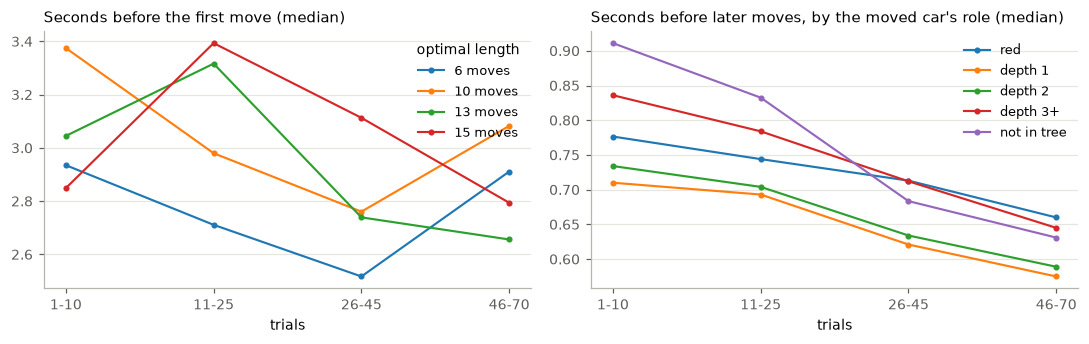

In [8]:
firsts = ppl_mv[ppl_mv.move == 0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for L, d in firsts.groupby("optimal length"):
    m = d.groupby("block", observed=True).seconds.median()
    axes[0].plot(m.index.astype(str), m.values, marker="o", ms=3, lw=1.4, label=f"{L} moves")
axes[0].set_title("Seconds before the first move (median)")
axes[0].legend(title="optimal length")
later = ppl_mv[ppl_mv.move > 0]
for role in ["red", "depth 1", "depth 2", "depth 3+", "not in tree"]:
    m = later[later.role == role].groupby("block", observed=True).seconds.median()
    axes[1].plot(m.index.astype(str), m.values, marker="o", ms=3, lw=1.4, label=role)
axes[1].set_title("Seconds before later moves, by the moved car's role (median)")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("trials")
    tidy(ax)
plt.tight_layout()
plt.show()

## 6. Summary: which measures separate the models, and which model is closest

For each scalar measure: people's value, each model's, and the model closest to people.

In [9]:
mv["optimal move"] = mv.after < mv.distance
mv["worse move"] = mv.after > mv.distance
mv["not in tree"] = mv.role == "not in tree"
mv["depth 1"] = mv.role == "depth 1"
mv["red"] = mv.role == "red"
scal = ["optimal move", "worse move", "new best", "board seen", "undo", "placement seen", "red", "depth 1",
        "not in tree", "same car", "full slide"]
tab = mv.groupby("source", observed=True)[scal].mean().T
tab["closest"] = (tab[list(SOURCES)[1:]].sub(tab["people"], axis=0).abs()).idxmin(axis=1)
tab["spread"] = tab[list(SOURCES)[1:]].max(axis=1) - tab[list(SOURCES)[1:]].min(axis=1)
tab.round(3)

source,people,AND-OR (paper),AND-OR (network),intuition,forward,random,"intuition, soft memory","forward, soft memory","forward, fitted","value planner, soft memory",closest,spread
optimal move,0.507,0.351,0.415,0.344,0.466,0.242,0.345,0.445,0.411,0.410,forward,0.224
worse move,0.198,0.290,0.271,0.252,0.188,0.223,0.267,0.207,0.229,0.248,"forward, soft memory",0.102
new best,0.338,0.079,0.161,0.109,0.287,0.044,0.095,0.249,0.195,0.173,forward,0.243
board seen,0.145,0.245,0.360,0.117,0.057,0.091,0.283,0.131,0.297,0.355,"forward, soft memory",0.303
undo,0.061,0.052,0.159,0.000,0.000,0.000,0.101,0.042,0.068,0.113,"forward, fitted",0.159
placement seen,0.489,0.785,0.727,0.751,0.530,0.819,0.772,0.576,0.694,0.721,forward,0.289
red,0.112,0.066,0.229,0.074,0.110,0.063,0.085,0.112,0.112,0.108,"forward, fitted",0.166
depth 1,0.264,0.279,0.245,0.282,0.284,0.268,0.272,0.277,0.279,0.279,random,0.038
not in tree,0.034,0.101,0.024,0.060,0.038,0.097,0.064,0.038,0.038,0.040,"forward, fitted",0.077
same car,0.079,0.118,0.262,0.124,0.123,0.121,0.229,0.164,0.199,0.236,AND-OR (paper),0.144


## 7. At matched efficiency

Many measures above track efficiency: a solver that wastes fewer moves makes more optimal moves and more new closest
approaches, whatever its style. To separate style from efficiency, the same measures on solved attempts of 1.5-3 ×
optimal only (mean about 2.0-2.3 for every source; random has a single such attempt).

In [10]:
keys = ["source", "who", "instance", "attempt"]
m = mv.merge(att[keys + ["ratio"]], on=keys)
m = m[(m.ratio >= 1.5) & (m.ratio <= 3) & m.solved]
matched = m.groupby("source", observed=True)[scal].mean().T
first_rows = m.drop_duplicates(keys)
matched.loc["attempts"] = first_rows.groupby("source", observed=True).size()
matched.loc["mean moves / optimal"] = first_rows.groupby("source", observed=True).ratio.mean()
matched.round(3)

source,people,AND-OR (paper),AND-OR (network),intuition,forward,random,"intuition, soft memory","forward, soft memory","forward, fitted","value planner, soft memory"
optimal move,0.581,0.554,0.614,0.559,0.588,0.583,0.573,0.582,0.592,0.609
worse move,0.141,0.128,0.120,0.111,0.097,0.083,0.116,0.097,0.102,0.116
new best,0.440,0.426,0.494,0.448,0.492,0.500,0.457,0.485,0.490,0.493
board seen,0.097,0.068,0.119,0.006,0.002,0.000,0.080,0.033,0.069,0.089
undo,0.056,0.042,0.079,0.000,0.000,0.000,0.059,0.022,0.038,0.059
placement seen,0.401,0.291,0.342,0.299,0.251,0.167,0.279,0.257,0.323,0.346
red,0.108,0.132,0.192,0.133,0.122,0.167,0.133,0.129,0.138,0.129
depth 1,0.271,0.269,0.234,0.258,0.257,0.417,0.246,0.254,0.276,0.275
not in tree,0.044,0.196,0.025,0.077,0.043,0.083,0.071,0.050,0.045,0.038
same car,0.074,0.092,0.140,0.094,0.111,0.000,0.145,0.123,0.142,0.150


## 8. Fitting the memory to people's revisits

The 10-board rule forbids the revisits people make. Its replacement: a move to a board the attempt last had `age`
moves ago (2 = undoing the last move) has its logit lowered by β × 0.5^(age / half-life)
(`forward.solve_forward(soft_memory=...)`). `experiments/fit_memory.py` plays the start network by intuition on the
70 layouts (20 runs each) over β 0.5-8 and half-lives 1-32 moves, plus the hard rule and no memory, and compares
the share of moves returning to a board, by age, with people's - on solved attempts of 1.5-3 × optimal for both.
Misfit: Σ over age bins of (model − people)² / people.

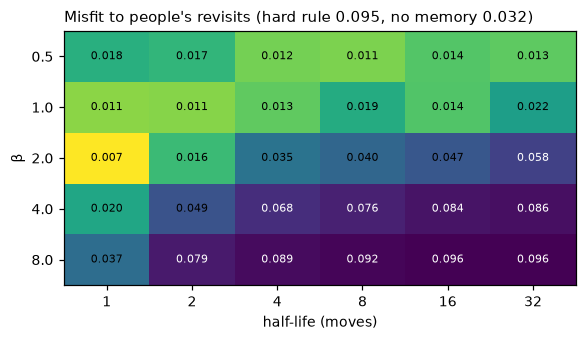

,2,3-4,5-8,9-16,17+,misfit,matched attempts,solved,moves / optimal (solved)
people,0.0563,0.0171,0.0142,0.0069,0.0023,NaN,NaN,NaN,NaN
"beta 2, half-life 1",0.0627,0.0139,0.0100,0.0033,0.0000,0.0068,279.0,0.5829,3.8465
"beta 1, half-life 2",0.0656,0.0141,0.0080,0.0017,0.0000,0.0109,304.0,0.5957,3.7142
"beta 0.5, half-life 8",0.0624,0.0147,0.0062,0.0019,0.0000,0.0114,302.0,0.5957,3.8285
no memory,0.0904,0.0191,0.0051,0.0019,0.0004,0.0318,248.0,0.5521,3.8329
"hard, last 10 boards",0.0000,0.0000,0.0000,0.0008,0.0003,0.0948,347.0,0.6429,3.6656


In [11]:
sys.path.insert(0, os.path.join("..", "experiments"))
import fit_memory as fm

fit = fm.summarize(pd.read_csv(os.path.join(paths.MODELS, "summary", "memory_fit.csv")), fm.people_target()[0])
grid = fit.dropna(subset=["misfit"]).copy()
soft = grid[grid.index.str.startswith("beta")]
heat = pd.DataFrame({(b, h): soft.loc[f"beta {b}, half-life {h}", "misfit"] for b in fm.BETAS for h in fm.HALVES},
                    index=[0]).T[0].unstack()
fig, ax = plt.subplots(figsize=(6, 3))
im = ax.imshow(np.log10(heat.values), cmap="viridis_r", aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.3f}", ha="center", va="center", fontsize=7,
                color="white" if heat.values[i, j] > 0.05 else "black")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.set_xlabel("half-life (moves)")
ax.set_ylabel("β")
ax.set_title(f"Misfit to people's revisits (hard rule {grid.loc['hard, last 10 boards', 'misfit']:.3f}, "
             f"no memory {grid.loc['no memory', 'misfit']:.3f})")
plt.show()
target = fm.people_target()[0]
show = pd.concat([target.to_frame("people").T,
                  fit.loc[["beta 2, half-life 1", "beta 1, half-life 2", "beta 0.5, half-life 8", "no memory",
                           "hard, last 10 boards"]]])
show.round(4)

- **The hard rule fits worst of all** (0.095), worse even than no memory (0.032): people undo and revisit, and
  it forbids both.
- **People's memory is weak, not long.** The best fits form a ridge of mild penalties on a recent board: β 2 with a
  half-life of 1 move (0.007), β 1 with 2, β 0.5 with 4-8. What they share is an undo penalty of about 0.3-0.5
  logits - an undo is roughly 30-40% less likely than without memory. How fast it fades beyond that is not
  pinned down by these data. Strong memories (β 4-8 with any half-life) fit like the hard rule.
- **Even the best fits too few long loops**: people return to boards 5-16 moves old about twice as often (1.4% and
  0.7% of moves against 1.0% and 0.3%).
- **The weak memory costs the start student some solving**: about 0.58-0.60 solved within the cap against 0.64 with
  the hard rule, at the same moves / optimal. Adopting it in sessions would mean refitting the start (giving-up
  scale) to people.
- There is a tension with the forward planner: its *placement* novelty works best remembered for 20-80 moves
  (forward_planning.ipynb), while people's *board* memory looks short. The two may be different memories: a weak
  aversion to going straight back, and a longer sense of which car positions have been tried.

Sections 1-7 include the two soft-memory models (β 2, half-life 1). At matched efficiency (section 7), the intuition
student with it revisits boards (8.0%) and undoes (5.9%) about as people do (9.7%, 5.6%). The forward planner with
it still does so much less (3.3%, 2.2%): its novelty score keeps steering rollouts away from old placements, so its
memory needs fitting in the planner itself (section 9). Neither puts cars back where they were as often as people
(26-28% of moves against 40%), and the soft memory makes the intuition student move the same car twice in a row
more (14.5% against people's 7.4%).

## 9. Fitting the planner's memory

The forward planner has a second memory: novelty in its rollout score - λ × the car placements a rollout reaches
that the attempt hasn't had recently, fading with a novelty half-life. It steers the planner away from earlier
placements whatever the board memory allows, so with the fitted board memory it still revisits too little. `python
experiments/fit_memory.py planner` keeps the board memory at β 2, half-life 1 and fits λ (2-16) and the novelty
half-life (2-80 moves) to people's returns to a board **and** of the moved car to a spot it held before, by age
(misfit: the sum over both); references: no novelty (rollouts ranked by value alone) and the planner with the hard
rule. 10 runs per layout, matched attempts as before.

In [12]:
planner, want = fm.summarize_planner(pd.read_csv(os.path.join(paths.MODELS, "summary", "memory_fit_planner.csv")))
show = pd.concat([want.to_frame("people").T, planner.sort_values("misfit")])
show[list(want.index) + ["board misfit", "car misfit", "misfit", "solved", "moves / optimal (solved)"]].round(3)

,2,3-4,5-8,9-16,17+,car 2,car 3-4,car 5-8,car 9-16,car 17+,board misfit,car misfit,misfit,solved,moves / optimal (solved)
people,0.056,0.017,0.014,0.007,0.002,0.056,0.093,0.126,0.094,0.031,NaN,NaN,NaN,NaN,NaN
"value only, soft memory",0.062,0.018,0.010,0.004,0.001,0.062,0.095,0.090,0.065,0.031,0.004,0.020,0.024,0.787,2.282
"lam 2, novelty half-life 2",0.037,0.012,0.010,0.004,0.001,0.037,0.081,0.102,0.078,0.026,0.011,0.016,0.028,0.820,2.207
"lam 2, novelty half-life 80",0.040,0.012,0.007,0.003,0.002,0.040,0.068,0.084,0.073,0.031,0.012,0.030,0.042,0.836,2.194
"lam 2, novelty half-life 5",0.031,0.014,0.011,0.003,0.001,0.031,0.082,0.093,0.075,0.027,0.016,0.026,0.043,0.830,2.211
"lam 2, novelty half-life 20",0.035,0.011,0.006,0.002,0.000,0.035,0.073,0.080,0.077,0.030,0.020,0.032,0.052,0.840,2.165
"lam 8, novelty half-life 2",0.024,0.009,0.006,0.003,0.001,0.024,0.060,0.094,0.090,0.030,0.030,0.038,0.069,0.823,2.138
"lam 4, novelty half-life 2",0.023,0.010,0.003,0.005,0.000,0.023,0.065,0.091,0.090,0.027,0.033,0.039,0.072,0.826,2.200
"lam 4, novelty half-life 20",0.031,0.009,0.004,0.002,0.000,0.031,0.062,0.072,0.077,0.032,0.026,0.048,0.074,0.866,2.177
"lam 4, novelty half-life 5",0.026,0.007,0.004,0.006,0.001,0.026,0.058,0.084,0.086,0.034,0.030,0.045,0.075,0.850,2.160


- **People's revisits ask for little or no novelty.** The best fits are the planner with no novelty at all (0.024)
  and λ 2 with a 2-move novelty half-life (0.028); every λ of 4 or more fits worse, and the performance-tuned
  planner (λ 16, half-life 80, hard rule) fits worst (0.205). People put a car back where it was on 40% of moves
  (at about 2 × optimal) - optimal routes do so on 11% - and novelty forbids exactly that.
- **The cost is solving**: within the cap, 0.79 (no novelty) and 0.82 (λ 2) against 0.89-0.91 for strong novelty,
  at about the same moves / optimal when solved (2.2-2.3).
- **In the full profile** (sections 1-7), the no-novelty planner with the soft memory comes closest to people on
  revisits (boards 8.9%, undo 5.9%, car returns 35% against 9.7%, 5.6%, 40%) and on cars outside the tree (3.8%
  against 4.4%). It still moves the same car twice in a row twice as often (15% against 7.4%), as every soft-memory
  model does.
- So the novelty that made the planner a strong solver is not what people show. Their search looks like
  value-guided lookahead with only a mild aversion to undoing, which leaves the question of what makes people
  efficient open: the value head here is the start network's.

## Takeaways

- **Optimal moves and new closest approaches mostly measure efficiency.** Pooled over all moves, the forward planner
  looks closest to people on them, but at matched efficiency every model makes optimal moves at about people's rate
  (0.55-0.61 against 0.58). Profiles by distance to the goal still differ: people stay better than every model in
  the middle of a puzzle (distance 6-9).
- **People revisit and undo; the memory-bound models cannot.** At matched efficiency people return to an earlier board
  on 10% of moves and undo the last move on 6%, like the two AND-OR models (7-12%, 4-8%). The intuition student and
  the forward planner, barred from the last 10 boards, almost never do (0-0.6%). The hard 10-board rule is not
  human; a fading novelty memory, fitted to people's revisits by age, is the natural replacement.
- **People put cars back where they were more than any model** (placement seen 0.40 against 0.25-0.34 at matched
  efficiency): returning a car to an earlier spot is common for them.
- **People rarely move cars outside the AND-OR tree** (3-4%), like the network-ordered AND-OR, the intuition student
  and the forward planner; the paper's AND-OR spreads its lapses over every legal move and moves such cars 10-20% of
  the time.
- **People slide cars as far as they go** (97% of moves, against 72-78% for every model). This may be the interface
  (dragging a car until it stops) rather than planning; worth checking before fitting on it.
- **Puzzle difficulty agrees only moderately** (Spearman 0.45-0.64 across the 70 layouts), best for the two AND-OR
  models on solve rate.
- **Over practice people improve on every measure a little**: more optimal moves (0.47 → 0.53), fewer revisits
  (0.17 → 0.12), fewer undos, less moving the same car twice, and faster moves (0.80 → 0.64 s median), while which
  cars they move stays the same.

Caveats: the models are all the start network or no network, one run of 10 per layout; models never give up; the
role of a car comes from the paper's tree, which models moves of at most 4 cells and caps its size (0.5% of boards
too large).